# Q3 Particle Gibbs-within-Gibbs sampler

This notebook implements a **Particle Gibbs sampler** for the stochastic volatility model. The latent trajectory is updated with a conditional particle filter, while the model parameters are updated conditionally on the sampled trajectory.

The MCMC iteration is:

1. Update the latent trajectory $x_{0:T}$ using a **conditional particle filter**, i.e. a Particle Gibbs update targeting $p(x_{0:T}\mid y_{0:T},\sigma^2,\beta^2,\rho)$.
2. Update $\beta^2\mid x_{0:T},y_{0:T}$ from its inverse-gamma full conditional.
3. Update $\sigma^2\mid x_{0:T},\rho$ from its inverse-gamma full conditional.
4. Update $\rho\mid x_{0:T},\sigma^2$ directly from its truncated-normal full conditional on $(-1,1)$.

All log returns are expressed in percentage units, i.e. $y_t\leftarrow 100y_t$. This rescales the posterior of $\beta^2$ by $100^2$, while the posteriors of $\sigma^2$, $\rho$, and the latent path are unchanged by the unit conversion.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

from scipy.stats import truncnorm


In [14]:
# ============================================================
# Load observations
# ============================================================

data = pd.read_csv('data.csv', header=None).values.squeeze()

# The assignment uses daily log returns. Many SV implementations use percentage returns.
# If your previous beta^2 trace was around 0.3--0.8, you were effectively using y * 100.
SCALE_Y = 1

y_all = SCALE_Y * data.astype(float)
y = y_all[:1000]

print('Length used:', len(y))
print('mean, std, min, max:', y.mean(), y.std(), y.min(), y.max())

Length used: 1000
mean, std, min, max: -9.965063853632377e-05 0.00553842759859716 -0.0313680517546209 0.0243586784579161


In [15]:
# ============================================================
# Model utilities
# Model: x_t = rho x_{t-1} + sigma eps_t
#        y_t | x_t ~ N(0, beta2 * exp(x_t))
# ============================================================

def log_obs_density(y_t, x_t, beta2):
    return -0.5 * (np.log(2 * np.pi) + np.log(beta2) + x_t + y_t**2 / (beta2 * np.exp(x_t)))


def normalize_log_weights(logw):
    m = np.max(logw)
    w = np.exp(logw - m)
    s = np.sum(w)
    if not np.isfinite(s) or s <= 0:
        return np.ones_like(w) / len(w)
    return w / s


def inverse_gamma_sample(shape, scale, rng):
    # IG(shape, scale) density proportional to x^{-shape-1} exp(-scale/x)
    return 1.0 / rng.gamma(shape, 1.0 / scale)

In [16]:
# ============================================================
# Conditional particle filter for Particle Gibbs
# ============================================================

def conditional_particle_filter(y, N, sigma2, beta2, rho, x_ref, rng):
    T = len(y)
    sigma = np.sqrt(sigma2)

    particles = np.empty((N, T))
    ancestors = np.empty((N, T), dtype=int)
    weights = np.empty((N, T))

    # t = 0: x_0 ~ N(0, 0.01), with the last particle fixed to x_ref[0]
    particles[:-1, 0] = rng.normal(0.0, np.sqrt(0.01), size=N-1)
    particles[-1, 0] = x_ref[0]
    ancestors[:, 0] = np.arange(N)

    logw = log_obs_density(y[0], particles[:, 0], beta2)
    weights[:, 0] = normalize_log_weights(logw)

    for t in range(1, T):
        # Resample ancestors for non-reference particles
        a = rng.choice(N, size=N-1, p=weights[:, t-1])
        ancestors[:-1, t] = a
        ancestors[-1, t] = N-1  # conditional path ancestor

        # Propagate non-reference particles
        particles[:-1, t] = rho * particles[a, t-1] + sigma * rng.normal(size=N-1)
        particles[-1, t] = x_ref[t]

        logw = log_obs_density(y[t], particles[:, t], beta2)
        weights[:, t] = normalize_log_weights(logw)

    # Sample one full trajectory by tracing ancestors backwards
    x_new = np.empty(T)
    idx = rng.choice(N, p=weights[:, -1])
    x_new[-1] = particles[idx, -1]

    for t in range(T-1, 0, -1):
        idx = ancestors[idx, t]
        x_new[t-1] = particles[idx, t-1]

    return x_new

In [17]:
# ============================================================
# Gibbs updates for sigma^2, beta^2, and rho
# ============================================================

def sample_beta2_gibbs(y, x, a=1.0, b=1.0, rng=rng):
    """
    beta^2 | x, y ~ IG(a + T/2, b + 0.5 * sum_t y_t^2 exp(-x_t)).
    IG(shape, scale) density is proportional to z^(-shape-1) exp(-scale/z).
    """
    T = len(y)
    shape = a + T / 2.0
    scale = b + 0.5 * np.sum(y**2 * np.exp(-x))
    return inverse_gamma_sample(shape, scale, rng)


def sample_sigma2_gibbs(x, rho, a=1.0, b=1.0, rng=rng):
    """
    sigma^2 | x, rho ~ IG(a + (T-1)/2, b + 0.5 * sum_t (x_t - rho x_{t-1})^2).
    Here x has length T, so transitions are t=1,...,T-1 in Python indexing.
    """
    resid = x[1:] - rho * x[:-1]
    shape = a + len(resid) / 2.0
    scale = b + 0.5 * np.sum(resid**2)
    return inverse_gamma_sample(shape, scale, rng)


def sample_rho_gibbs(x, sigma2, rng=rng):
    """
    rho | x, sigma^2, y ~ N(mu_rho, V_rho) truncated to (-1, 1),
    because X_0 ~ N(0, 0.01) does not depend on rho and rho ~ U(-1, 1).

    mu_rho = sum_{t=1}^{T-1} x_t x_{t-1} / sum_{t=1}^{T-1} x_{t-1}^2
    V_rho  = sigma^2 / sum_{t=1}^{T-1} x_{t-1}^2
    """
    x_prev = x[:-1]
    x_next = x[1:]

    Sxx = np.sum(x_prev**2)
    Sxy = np.sum(x_prev * x_next)

    # Degenerate fallback is practically never used, but keeps the sampler robust.
    if Sxx <= 1e-300:
        return rng.uniform(-1.0, 1.0)

    mu = Sxy / Sxx
    sd = np.sqrt(sigma2 / Sxx)

    a = (-1.0 - mu) / sd
    b = (1.0 - mu) / sd

    return truncnorm.rvs(a, b, loc=mu, scale=sd, random_state=rng)


In [18]:
# ============================================================
# Particle Gibbs-within-Gibbs sampler
# ============================================================

def particle_gibbs_sv(
    y,
    N=500,
    M=20000,
    sigma2_init=0.2,
    beta2_init=None,
    rho_init=0.95,
    a_sigma=1.0,
    b_sigma=1.0,
    a_beta=1.0,
    b_beta=1.0,
    rng=rng,
):
    T = len(y)

    if beta2_init is None:
        beta2_init = max(np.var(y), 1e-6)

    sigma2_path = np.empty(M)
    beta2_path = np.empty(M)
    rho_path = np.empty(M)
    x_path = np.empty((M, T))
    rho_drawn = np.ones(M, dtype=bool)

    sigma2 = sigma2_init
    beta2 = beta2_init
    rho = rho_init

    # Initial latent path
    x = rng.normal(0.0, np.sqrt(0.01), size=T)

    for m in range(M):
        # 1. Particle Gibbs update for the full latent trajectory
        x = conditional_particle_filter(y, N, sigma2, beta2, rho, x, rng)

        # 2. Exact Gibbs updates for inverse-gamma variance parameters
        beta2 = sample_beta2_gibbs(y, x, a=a_beta, b=b_beta, rng=rng)
        sigma2 = sample_sigma2_gibbs(x, rho, a=a_sigma, b=b_sigma, rng=rng)

        # 3. Exact Gibbs update for rho from its truncated-normal full conditional
        rho = sample_rho_gibbs(x, sigma2, rng=rng)

        sigma2_path[m] = sigma2
        beta2_path[m] = beta2
        rho_path[m] = rho
        x_path[m] = x

        if (m + 1) % 500 == 0:
            print(
                f'iter {m+1}/{M}: '
                f'sigma2={sigma2:.4g}, beta2={beta2:.4g}, rho={rho:.5f}'
            )

    return sigma2_path, beta2_path, rho_path, x_path, rho_drawn


In [19]:
# ============================================================
# Run sampler
# Increase M_iter if the trace plots still show slow movement.
# ============================================================

N_particles = 500
M_iter = 10000

sigma2_path, beta2_path, rho_path, x_path, rho_drawn = particle_gibbs_sv(
    y,
    N=N_particles,
    M=M_iter,
    sigma2_init=0.2,
    beta2_init=np.var(y),
    rho_init=0.95,
    rng=rng,
)

#print('rho is updated by direct truncated-normal Gibbs sampling.')


iter 500/10000: sigma2=0.1081, beta2=0.04589, rho=0.99885
iter 1000/10000: sigma2=0.1253, beta2=0.1097, rho=0.99961
iter 1500/10000: sigma2=0.1035, beta2=0.1162, rho=0.99896
iter 2000/10000: sigma2=0.1657, beta2=0.07999, rho=0.99722
iter 2500/10000: sigma2=0.1831, beta2=0.1211, rho=0.99749
iter 3000/10000: sigma2=0.1422, beta2=0.09653, rho=0.99811
iter 3500/10000: sigma2=0.1312, beta2=0.0852, rho=0.99527
iter 4000/10000: sigma2=0.152, beta2=0.07363, rho=0.99878
iter 4500/10000: sigma2=0.1301, beta2=0.1341, rho=0.99988
iter 5000/10000: sigma2=0.1419, beta2=0.11, rho=0.99897
iter 5500/10000: sigma2=0.1273, beta2=0.06449, rho=0.99798
iter 6000/10000: sigma2=0.1505, beta2=0.1316, rho=0.99863
iter 6500/10000: sigma2=0.146, beta2=0.18, rho=0.99989
iter 7000/10000: sigma2=0.1605, beta2=0.1009, rho=0.99904
iter 7500/10000: sigma2=0.202, beta2=0.1221, rho=0.99788
iter 8000/10000: sigma2=0.1489, beta2=0.1576, rho=0.99928
iter 8500/10000: sigma2=0.1401, beta2=0.1618, rho=0.99913
iter 9000/10000: 

In [20]:
# ============================================================
# Store and summarise posterior samples
# ============================================================

from pathlib import Path

burn_in = 2000
posterior_cache = Path("q3_pg_posterior_samples.npz")

# Save the current Particle Gibbs output so diagnostics/prediction can be re-run
# without repeating the expensive conditional-particle-filter MCMC.
np.savez_compressed(
    posterior_cache,
    sigma2_path=sigma2_path,
    beta2_path=beta2_path,
    rho_path=rho_path,
    x_path=x_path,
    rho_drawn=rho_drawn,
    y_all=y_all,
    burn_in=burn_in,
)

sigma2_post = sigma2_path[burn_in:]
beta2_post = beta2_path[burn_in:]
rho_post = rho_path[burn_in:]
x_post = x_path[burn_in:]

posterior_summary = pd.DataFrame({
    "mean": [np.mean(sigma2_post), np.mean(beta2_post), np.mean(rho_post)],
    "sd": [np.std(sigma2_post, ddof=1), np.std(beta2_post, ddof=1), np.std(rho_post, ddof=1)],
    "2.5%": [np.quantile(sigma2_post, 0.025), np.quantile(beta2_post, 0.025), np.quantile(rho_post, 0.025)],
    "50%": [np.quantile(sigma2_post, 0.5), np.quantile(beta2_post, 0.5), np.quantile(rho_post, 0.5)],
    "97.5%": [np.quantile(sigma2_post, 0.975), np.quantile(beta2_post, 0.975), np.quantile(rho_post, 0.975)],
}, index=[r"$\sigma^2$", r"$\beta^2$", r"$\rho$"])

print("Saved Particle Gibbs posterior samples to:", posterior_cache)
print("Posterior sample sizes:")
print("sigma2_post:", sigma2_post.shape)
print("beta2_post :", beta2_post.shape)
print("rho_post   :", rho_post.shape)
print("x_post     :", x_post.shape)
print("rho update: direct truncated-normal Gibbs draw (no acceptance step)")
posterior_summary


Saved Particle Gibbs posterior samples to: q3_pg_posterior_samples.npz
Posterior sample sizes:
sigma2_post: (8000,)
beta2_post : (8000,)
rho_post   : (8000,)
x_post     : (8000, 1000)
rho update: direct truncated-normal Gibbs draw (no acceptance step)


,mean,sd,2.5%,50%,97.5%
$\sigma^2$,0.150318,0.024242,0.111211,0.147358,0.208433
$\beta^2$,0.124595,0.040362,0.063969,0.120824,0.210767
$\rho$,0.998644,0.000983,0.996339,0.998839,0.999937


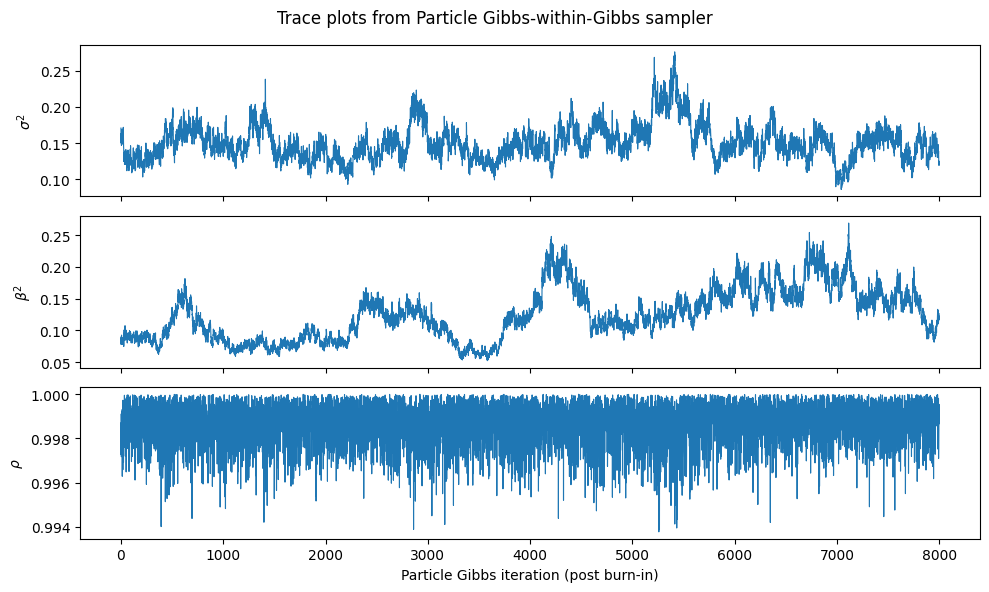

In [21]:
# ============================================================
# Diagnostics: trace plots (post burn-in)
# ============================================================

fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True)

axes[0].plot(sigma2_post, linewidth=0.8)
axes[0].set_ylabel(r'$\sigma^2$')

axes[1].plot(beta2_post, linewidth=0.8)
axes[1].set_ylabel(r'$\beta^2$')

axes[2].plot(rho_post, linewidth=0.8)
axes[2].set_ylabel(r'$\rho$')
axes[2].set_xlabel('Particle Gibbs iteration (post burn-in)')

fig.suptitle('Trace plots from Particle Gibbs-within-Gibbs sampler')
plt.tight_layout()
plt.show()


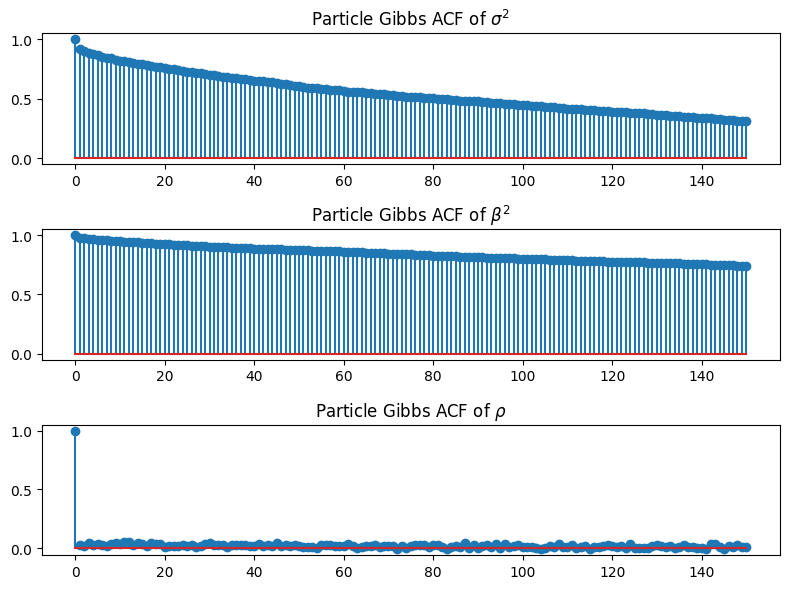

In [28]:
# ============================================================
# Diagnostics: ACF
# ============================================================

def acf(x, max_lag=50):
    x = np.asarray(x)
    x = x - np.mean(x)
    n = len(x)

    var = np.dot(x, x) / n
    vals = [1.0]

    for lag in range(1, max_lag + 1):
        val = np.dot(x[:-lag], x[lag:]) / ((n - lag) * var)
        vals.append(val)

    return np.array(vals)


acf_sigma2 = acf(sigma2_post, max_lag=150)
acf_beta2 = acf(beta2_post, max_lag=150)
acf_rho = acf(rho_post, max_lag=150)

plt.figure(figsize=(8, 6))
plt.subplot(3, 1, 1)
plt.stem(range(len(acf_sigma2)), acf_sigma2)
plt.title(r'Particle Gibbs ACF of $\sigma^2$')
plt.subplot(3, 1, 2)
plt.stem(range(len(acf_beta2)), acf_beta2)
plt.title(r'Particle Gibbs ACF of $\beta^2$')
plt.subplot(3, 1, 3)
plt.stem(range(len(acf_rho)), acf_rho)
plt.title(r'Particle Gibbs ACF of $\rho$')
plt.tight_layout()
plt.show()

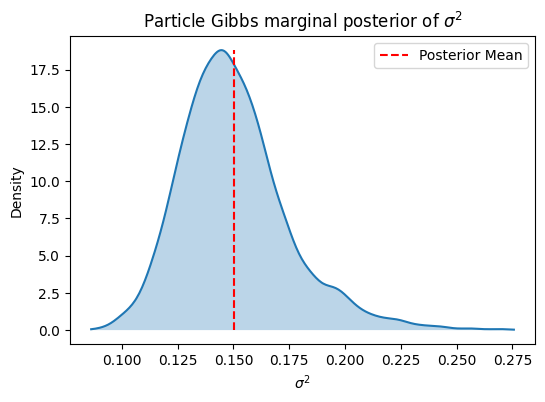

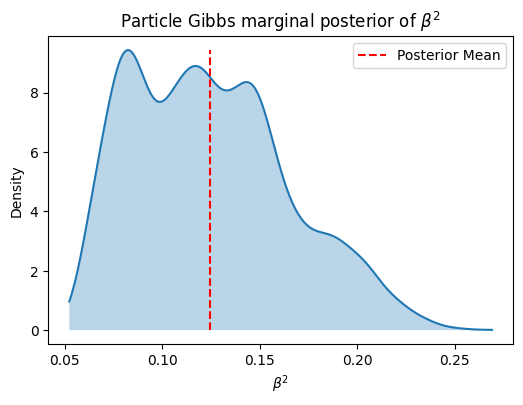

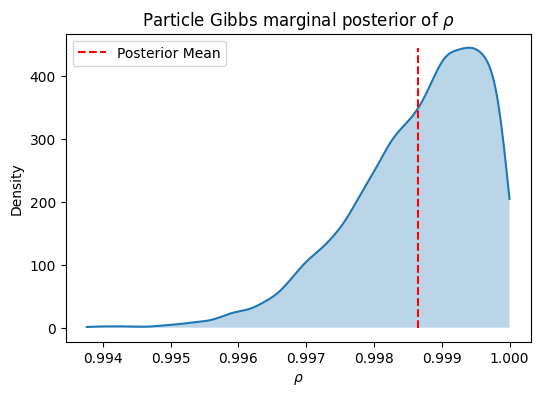

In [23]:
# ============================================================
# Marginal posterior densities
# ============================================================
from scipy.stats import gaussian_kde

# sigma^2
x_sigma = np.linspace(np.min(sigma2_post), np.max(sigma2_post), 300)
kde_sigma = gaussian_kde(sigma2_post)
y_sigma = kde_sigma(x_sigma)

plt.figure(figsize=(6,4))
plt.plot(x_sigma, y_sigma)
plt.vlines(np.mean(sigma2_post), 0, np.max(y_sigma), color='red', linestyle='--', label='Posterior Mean')
plt.fill_between(x_sigma, y_sigma, alpha=0.3)
plt.xlabel(r'$\sigma^2$')
plt.ylabel('Density')
plt.title(r'Particle Gibbs marginal posterior of $\sigma^2$')
plt.legend()
plt.show()

# beta^2
x_beta = np.linspace(np.min(beta2_post), np.max(beta2_post), 300)
kde_beta = gaussian_kde(beta2_post)
y_beta = kde_beta(x_beta)

plt.figure(figsize=(6,4))
plt.plot(x_beta, y_beta)
plt.vlines(np.mean(beta2_post), 0, np.max(y_beta), color='red', linestyle='--', label='Posterior Mean')
plt.fill_between(x_beta, y_beta, alpha=0.3)
plt.xlabel(r'$\beta^2$')
plt.ylabel('Density')
plt.title(r'Particle Gibbs marginal posterior of $\beta^2$')
plt.legend()
plt.show()

# rho
x_rho = np.linspace(np.min(rho_post), np.max(rho_post), 300)
kde_rho = gaussian_kde(rho_post)
y_rho = kde_rho(x_rho)

plt.figure(figsize=(6,4))
plt.plot(x_rho, y_rho)
plt.vlines(np.mean(rho_post), 0, np.max(y_rho), color='red', linestyle='--', label='Posterior Mean')
plt.fill_between(x_rho, y_rho, alpha=0.3)
plt.xlabel(r'$\rho$')
plt.ylabel('Density')
plt.title(r'Particle Gibbs marginal posterior of $\rho$')
plt.legend()
plt.show()

sigma2_post: (8000,)
beta2_post : (8000,)
rho_post   : (8000,)
x_path_post: (8000, 1000)


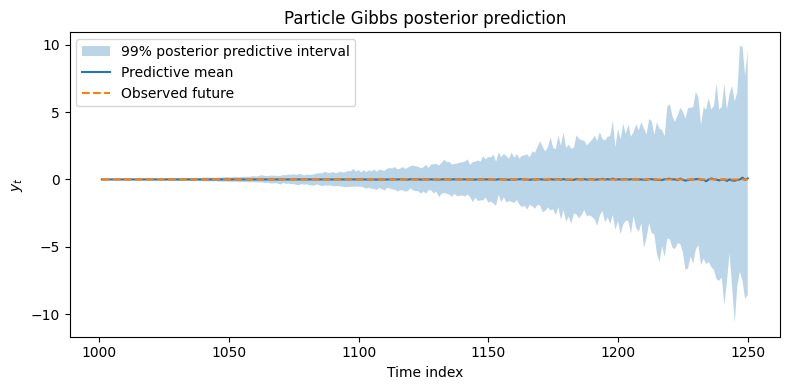

In [29]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Posterior predictive simulation for stochastic volatility model
# ============================================================

def predictive_simulation_sv(
    sigma2_post,
    beta2_post,
    rho_post,
    x_path_post,
    H,
    rng=None
):
    if rng is None:
        rng = np.random.default_rng()

    sigma2_post = np.asarray(sigma2_post).squeeze()
    beta2_post = np.asarray(beta2_post).squeeze()
    rho_post = np.asarray(rho_post).squeeze()
    x_path_post = np.asarray(x_path_post)

    M = len(sigma2_post)

    assert len(beta2_post) == M, "beta2_post has different length."
    assert len(rho_post) == M, "rho_post has different length."
    assert x_path_post.shape[0] == M, "x_path_post must have the same number of rows as posterior samples."

    y_future_samples = np.zeros((M, H))
    x_future_samples = np.zeros((M, H))

    for m in range(M):
        sigma = np.sqrt(sigma2_post[m])
        beta = np.sqrt(beta2_post[m])
        rho = rho_post[m]

        # terminal latent state x_T from the same posterior draw
        x_curr = x_path_post[m, -1]

        for h in range(H):
            x_next = rho * x_curr + sigma * rng.normal()
            y_next = beta * np.exp(x_next / 2) * rng.normal()

            x_future_samples[m, h] = x_next
            y_future_samples[m, h] = y_next

            x_curr = x_next

    return y_future_samples, x_future_samples


# ============================================================
# Prepare posterior samples
# ============================================================

print("sigma2_post:", sigma2_post.shape)
print("beta2_post :", beta2_post.shape)
print("rho_post   :", rho_post.shape)
print("x_path_post:", x_post.shape)


# ============================================================
# Produce future samples
# ============================================================

T_train = 1000
H = len(y_all) - T_train

y_future_samples, x_future_samples = predictive_simulation_sv(
    sigma2_post=sigma2_post,
    beta2_post=beta2_post,
    rho_post=rho_post,
    x_path_post=x_post,
    H=H,
    rng=rng
)


# ============================================================
# Posterior predictive summaries
# ============================================================

pred_mean = np.mean(y_future_samples, axis=0)
pred_median = np.median(y_future_samples, axis=0)

lower = np.quantile(y_future_samples, 0.005, axis=0)
upper = np.quantile(y_future_samples, 0.995, axis=0)


# ============================================================
# True future observations for comparison
# ============================================================

y_all = np.asarray(y_all).squeeze()

y_true_future = y_all[T_train:T_train + H]
n_grid = np.arange(T_train + 1, T_train + H + 1)

assert len(y_true_future) == H
assert len(n_grid) == H


# ============================================================
# Plot: short horizon
# ============================================================

plt.figure(figsize=(8, 4))
plt.fill_between(
        n_grid,
        lower,
        upper,
        alpha=0.3,
        label="99% posterior predictive interval"
)

plt.plot(n_grid, pred_mean, label="Predictive mean")
plt.plot(n_grid, y_true_future, "--", label="Observed future")
plt.xlabel("Time index")
plt.ylabel(r"$y_t$")
plt.title("Particle Gibbs posterior prediction")
plt.legend()
plt.tight_layout()
plt.show()

## Suggested report comment

We use a Particle Gibbs-within-Gibbs sampler. At each MCMC iteration, the latent volatility path is updated using a conditional particle filter, which leaves $p(x_{0:T}\mid y_{0:T},\sigma^2,\beta^2,\rho)$ invariant. Conditional on this sampled path, $\beta^2$ and $\sigma^2$ have inverse-gamma full conditionals, so they are updated by exact Gibbs steps. Since the initial condition is $X_0\sim N(0,0.01)$ and does not depend on $\rho$, the full conditional $p(\rho\mid x_{0:T},\sigma^2)$ is a normal density truncated to $(-1,1)$ under the uniform prior on $\rho$. We therefore update $\rho$ by direct truncated-normal Gibbs sampling rather than a random-walk Metropolis step. Posterior summaries, trace plots, ACF plots and predictive intervals are computed from the retained post-burn-in Particle Gibbs samples.
